In [1]:
pip install pandas numpy matplotlib seaborn jupyter

  Using cached isoduration-20.11.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached rfc3987_syntax-1.1.0-py3-none-any.whl.metadata (7.7 kB)
  Using cached uri_template-1.3.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached webcolors-25.10.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached lark-1.3.1-py3-none-any.whl.metadata (1.8 kB)
Using cached rfc3987_syntax-1.1.0-py3-none-any.whl (8.0 kB)
Using cached lark-1.3.1-py3-none-any.whl (113 kB)
Using cached webcolors-25.10.0-py3-none-any.whl (14 kB)
Using cached isoduration-20.11.0-py3-none-any.whl (11 kB)
Using cached uri_template-1.3.0-py3-none-any.whl (11 kB)

   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   -------------------- ------------------- 3/6 [fqdn]
   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [isoduration]

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("AS10-01.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (76817, 5)

Columns:
['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths']


,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
1,2020-01-23,Afghanistan,0,0,0
2,2020-01-24,Afghanistan,0,0,0
3,2020-01-25,Afghanistan,0,0,0
4,2020-01-26,Afghanistan,0,0,0


In [4]:
# Step 1: Basic Dataset Information

print("First 5 rows of the dataset:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

First 5 rows of the dataset:


,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
1,2020-01-23,Afghanistan,0,0,0
2,2020-01-24,Afghanistan,0,0,0
3,2020-01-25,Afghanistan,0,0,0
4,2020-01-26,Afghanistan,0,0,0



Dataset Shape:
(76817, 5)

Column Names:
['Date', 'Country', 'Confirmed', 'Recovered', 'Deaths']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76817 entries, 0 to 76816
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Date       76817 non-null  object
 1   Country    76817 non-null  object
 2   Confirmed  76817 non-null  int64 
 3   Recovered  76817 non-null  int64 
 4   Deaths     76817 non-null  int64 
dtypes: int64(3), object(2)
memory usage: 2.9+ MB

Statistical Summary:


,Confirmed,Recovered,Deaths
count,7.681700e+04,7.681700e+04,76817.000000
mean,7.728278e+05,2.053468e+05,14316.581603
std,3.217010e+06,1.347062e+06,55857.909104
min,0.000000e+00,0.000000e+00,0.000000
25%,2.362000e+03,0.000000e+00,34.000000
50%,3.031800e+04,3.040000e+02,491.000000
75%,2.781360e+05,2.391000e+04,5855.000000
max,4.304210e+07,3.097475e+07,662185.000000


In [5]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Percentage of missing values
print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

Missing Values:
Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
0

Missing Values Percentage:
Date         0.0
Country      0.0
Confirmed    0.0
Recovered    0.0
Deaths       0.0
dtype: float64


In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df_clean.isnull().sum())

# Fill missing numerical values with 0
numeric_cols = df_clean.select_dtypes(include="number").columns
df_clean[numeric_cols] = df_clean[numeric_cols].fillna(0)

# Remove rows where important text/date fields are missing
df_clean.dropna(subset=["Country", "Date"], inplace=True)

# Convert Date column to datetime
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

df_clean.head()

Missing values before cleaning:
Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64

Missing values after cleaning:
Date         0
Country      0
Confirmed    0
Recovered    0
Deaths       0
dtype: int64

Cleaned dataset shape: (76817, 5)


,Date,Country,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,0,0,0
1,2020-01-23,Afghanistan,0,0,0
2,2020-01-24,Afghanistan,0,0,0
3,2020-01-25,Afghanistan,0,0,0
4,2020-01-26,Afghanistan,0,0,0


Top 10 Countries by Confirmed Cases:


,Country,Confirmed
66095,India,43042097
20399,Brazil,30250077
52223,France,27874269
55487,Germany,23416663
76703,"Korea, South",16305752
70991,Italy,15659835
6527,Argentina,9060495
72623,Japan,7332261
67727,Iran,7205064
31823,Colombia,6089540


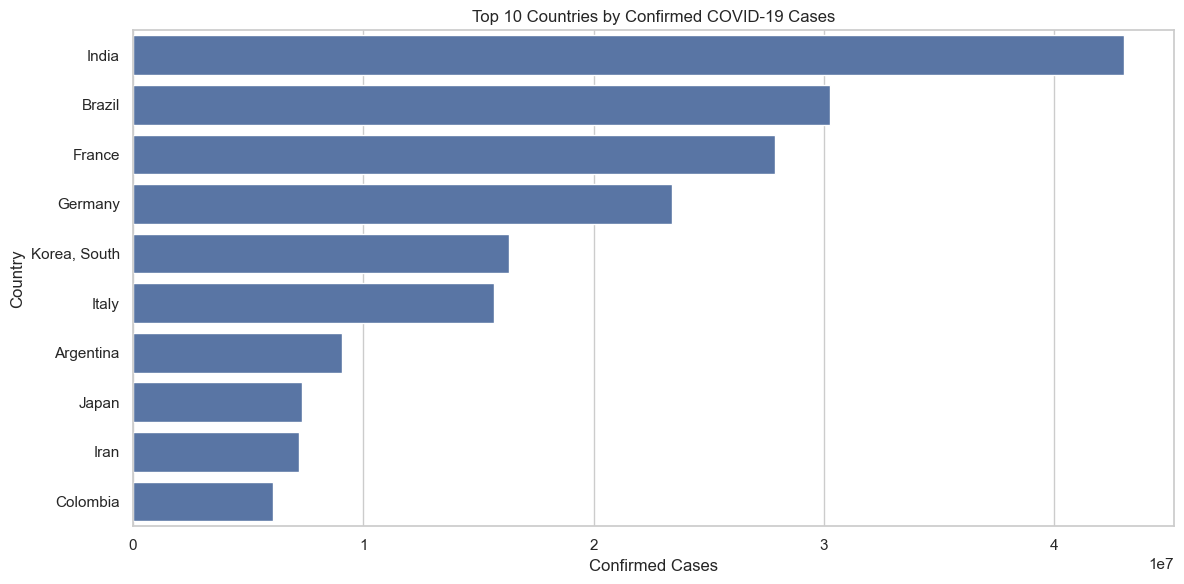

In [7]:
# Step 4: Country-wise COVID-19 Analysis

# Get the latest record for each country
latest_data = (
    df_clean.sort_values("Date")
    .groupby("Country")
    .tail(1)
    .copy()
)

# Top 10 countries by confirmed cases
top_cases = latest_data.nlargest(10, "Confirmed")

print("Top 10 Countries by Confirmed Cases:")
display(top_cases[["Country", "Confirmed"]])

# Bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_cases,
    x="Confirmed",
    y="Country"
)

plt.title("Top 10 Countries by Confirmed COVID-19 Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Top 10 Countries by Deaths:


,Country,Deaths
20399,Brazil,662185
66095,India,521751
70991,Italy,161602
66911,Indonesia,155844
52223,France,145159
67727,Iran,140800
31823,Colombia,139745
55487,Germany,132942
6527,Argentina,128344
30191,Chile,57231


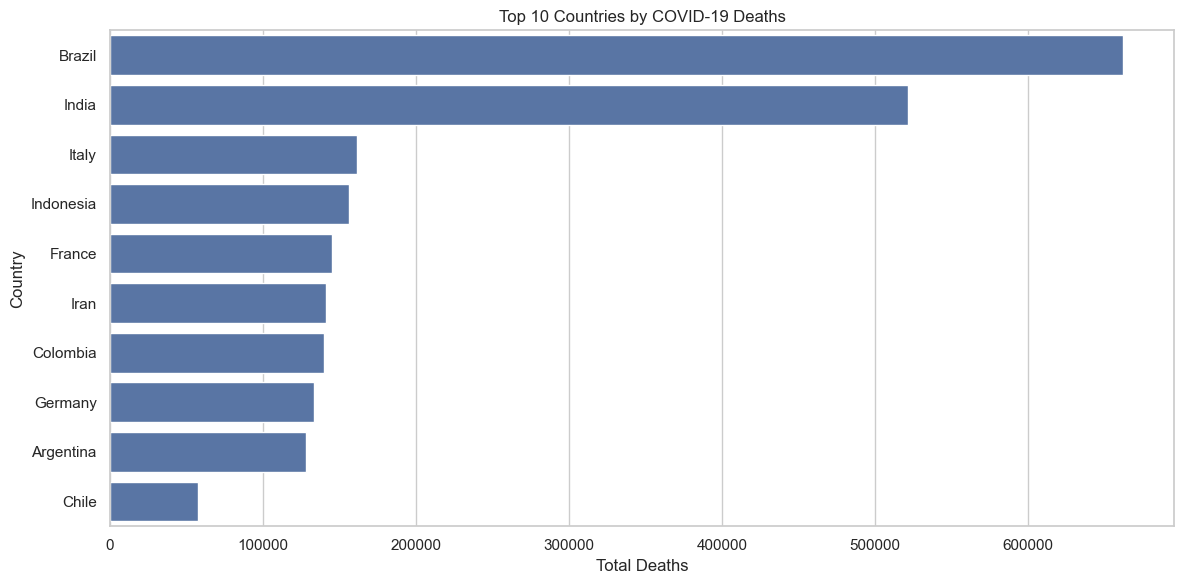

In [8]:
# Top 10 countries by reported deaths
top_deaths = latest_data.nlargest(10, "Deaths")

print("Top 10 Countries by Deaths:")
display(top_deaths[["Country", "Deaths"]])

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_deaths,
    x="Deaths",
    y="Country"
)

plt.title("Top 10 Countries by COVID-19 Deaths")
plt.xlabel("Total Deaths")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Top 10 Countries by Recoveries:


,Country,Recovered
76816,Kosovo,671
67727,Iran,0
9791,Azerbaijan,0
21215,Brunei,0
58751,Guatemala,0
71807,Jamaica,0
66095,India,0
66911,Indonesia,0
10607,Bahamas,0
53855,Gambia,0


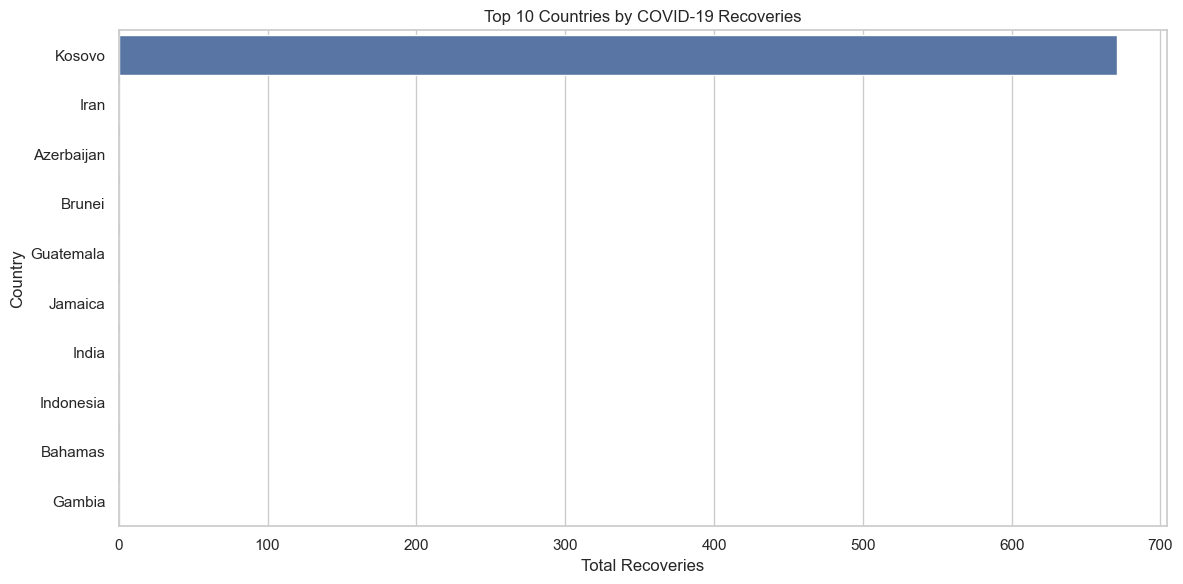

In [9]:
# Top 10 countries by reported recoveries
top_recovered = latest_data.nlargest(10, "Recovered")

print("Top 10 Countries by Recoveries:")
display(top_recovered[["Country", "Recovered"]])

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_recovered,
    x="Recovered",
    y="Country"
)

plt.title("Top 10 Countries by COVID-19 Recoveries")
plt.xlabel("Total Recoveries")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

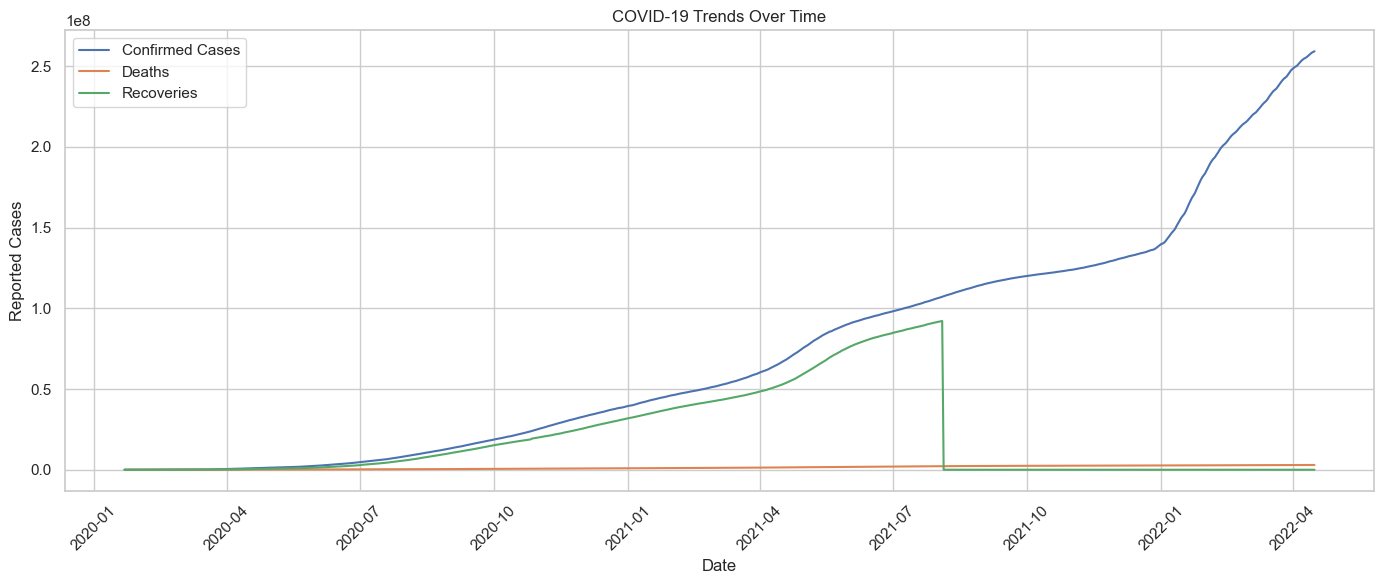

In [10]:
# Step 6: COVID-19 Trends Over Time

# Calculate daily global totals
daily_data = (
    df_clean.groupby("Date")[["Confirmed", "Deaths", "Recovered"]]
    .sum()
    .reset_index()
)

# Create line chart
plt.figure(figsize=(14, 6))

plt.plot(
    daily_data["Date"],
    daily_data["Confirmed"],
    label="Confirmed Cases"
)

plt.plot(
    daily_data["Date"],
    daily_data["Deaths"],
    label="Deaths"
)

plt.plot(
    daily_data["Date"],
    daily_data["Recovered"],
    label="Recoveries"
)

plt.title("COVID-19 Trends Over Time")
plt.xlabel("Date")
plt.ylabel("Reported Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation Matrix:


,Confirmed,Recovered,Deaths
Confirmed,1.000000,0.429960,0.912124
Recovered,0.429960,1.000000,0.444967
Deaths,0.912124,0.444967,1.000000


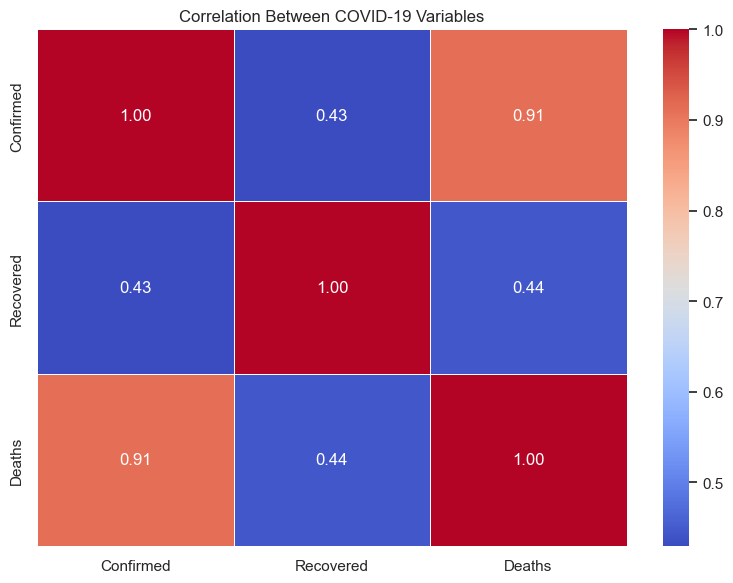

In [11]:
# Step 7: Correlation Heatmap

# Select numerical columns
corr_data = df_clean[
    ["Confirmed", "Recovered", "Deaths"]
]

# Calculate correlation
correlation = corr_data.corr()

print("Correlation Matrix:")
display(correlation)

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between COVID-19 Variables")
plt.tight_layout()
plt.show()

India COVID-19 Statistics:


,Date,Confirmed,Deaths,Recovered
66091,2022-04-12,43038016,521736,0
66092,2022-04-13,43039023,521737,0
66093,2022-04-14,43039972,521743,0
66094,2022-04-15,43040947,521747,0
66095,2022-04-16,43042097,521751,0


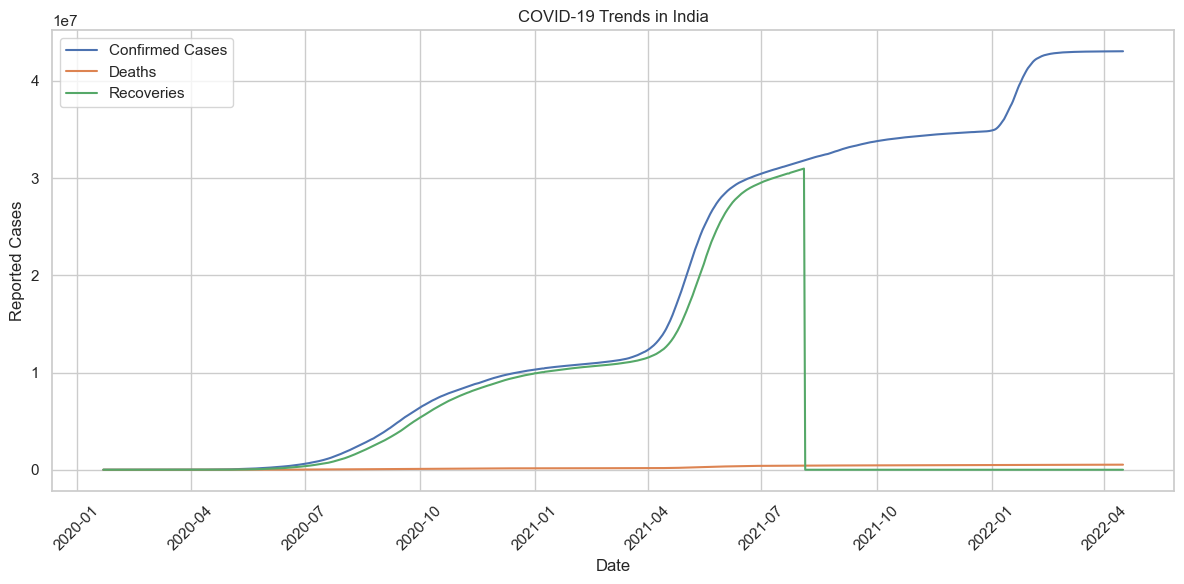

In [12]:
# Step 8: India COVID-19 Analysis

india_data = df_clean[
    df_clean["Country"].str.lower() == "india"
].copy()

india_data = india_data.sort_values("Date")

# Display latest statistics
print("India COVID-19 Statistics:")
display(
    india_data[["Date", "Confirmed", "Deaths", "Recovered"]].tail()
)

# Plot trends
plt.figure(figsize=(12, 6))

plt.plot(
    india_data["Date"],
    india_data["Confirmed"],
    label="Confirmed Cases"
)

plt.plot(
    india_data["Date"],
    india_data["Deaths"],
    label="Deaths"
)

plt.plot(
    india_data["Date"],
    india_data["Recovered"],
    label="Recoveries"
)

plt.title("COVID-19 Trends in India")
plt.xlabel("Date")
plt.ylabel("Reported Cases")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Step 9: Final Findings and Summary

print("=" * 45)
print("COVID-19 DATA ANALYSIS: FINAL FINDINGS")
print("=" * 45)

# Latest statistics for each country
latest_data = (
    df_clean.sort_values("Date")
    .groupby("Country")
    .tail(1)
)

# Country with highest confirmed cases
top_case = latest_data.loc[latest_data["Confirmed"].idxmax()]

# Country with highest deaths
top_death = latest_data.loc[latest_data["Deaths"].idxmax()]

# Country with highest recoveries
top_recovery = latest_data.loc[latest_data["Recovered"].idxmax()]

print("\n1. Total Countries Analyzed:", df_clean["Country"].nunique())
print("2. Total Records Analyzed:", len(df_clean))

print("\n3. Highest Reported Confirmed Cases:")
print(top_case["Country"], "-", f'{top_case["Confirmed"]:,}')

print("\n4. Highest Reported Deaths:")
print(top_death["Country"], "-", f'{top_death["Deaths"]:,}')

print("\n5. Highest Reported Recoveries:")
print(top_recovery["Country"], "-", f'{top_recovery["Recovered"]:,}')

print("\n6. Date Range:")
print(df_clean["Date"].min().date(), "to", df_clean["Date"].max().date())

print("\nAnalysis completed successfully!")

COVID-19 DATA ANALYSIS: FINAL FINDINGS

1. Total Countries Analyzed: 95
2. Total Records Analyzed: 76817

3. Highest Reported Confirmed Cases:
India - 43,042,097

4. Highest Reported Deaths:
Brazil - 662,185

5. Highest Reported Recoveries:
Kosovo - 671

6. Date Range:
2020-01-22 to 2022-04-16

Analysis completed successfully!
